In [1]:
%% MIT 18.03 Lecture 36: The Matrix Exponential e^{At} & Initial Value Problems
% Description: Demonstrates the Matrix Exponential and State Transition Matrix via Control Toolbox:
%              1) Upper-Triangular System A1 = [1, 1; 0, 2]: verifies e^{At} = Phi(t)*Phi(0)^{-1}
%                 and column-by-column generation via 'initial' from standard basis [1;0] and [0;1].
%              2) Defective Companion Double Integrator A2 = [0, 1; 0, 0]: verifies e^{At} = [1, t; 0, 1]
%                 and discrete ZOH state matrix Ad = e^{A*Ts} via 'c2d'.
%              3) Exponential Law & Commutativity check: e^A * e^B ~= e^{A+B} when A*B ~= B*A.
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, c2d, pole).
%
% % MBD Concept Mapping: Connects the fundamental matrix normalization Phi(t)*Phi(0)^{-1} to the
% %                      continuous State Transition Matrix (STM) and discrete-time ZOH sampling Ad = e^{A*Ts}.


clear; clc; close all;


%% =========================================================================
%% Part 1: Fundamental Matrix & e^{At} = Phi(t)*Phi(0)^{-1} (Sections [1]-[2])
%% =========================================================================
% Lecture Section [2] Example: A1 = [1, 1; 0, 2]
A1 = [1, 1;
      0, 2];
sys_A1 = ss(A1, zeros(2,1), eye(2), zeros(2,1));


% Eigenvectors: lambda1 = 1 -> v1 = [1; 0]; lambda2 = 2 -> v2 = [1; 1]
% Fundamental matrix at t = 0: Phi(0) = [v1, v2] = [1, 1; 0, 1]
Phi_0 = [1, 1;
         0, 1];
Phi_0_inv = inv(Phi_0); % [1, -1; 0, 1]


t_vec = linspace(0, 1.5, 400);


% Definition in Section [1]:
% Column 1 of e^{At} is the solution with u(0) = [1; 0]
% Column 2 of e^{At} is the solution with u(0) = [0; 1]
[col1_sim, ~] = initial(sys_A1, [1; 0], t_vec); % [e^t, 0]
[col2_sim, ~] = initial(sys_A1, [0; 1], t_vec); % [e^{2t} - e^t, e^{2t}]


% Analytical formula from Section [2]: e^{At} = [e^t, e^{2t} - e^t ; 0, e^{2t}]
eAt_11_exact = exp(t_vec);
eAt_12_exact = exp(2*t_vec) - exp(t_vec);
eAt_21_exact = zeros(size(t_vec));
eAt_22_exact = exp(2*t_vec);


err_col1 = max(abs(col1_sim(:,1) - eAt_11_exact(:)) + abs(col1_sim(:,2) - eAt_21_exact(:)));
err_col2 = max(abs(col2_sim(:,1) - eAt_12_exact(:)) + abs(col2_sim(:,2) - eAt_22_exact(:)));


fprintf('=== MIT 18.03 Lecture 36 Matrix Exponential Diagnostics ===\n');

=== MIT 18.03 Lecture 36 Matrix Exponential Diagnostics ===

In [2]:
fprintf('1) Upper-Triangular System A1 = [1, 1; 0, 2]\n');

1) Upper-Triangular System A1 = [1, 1; 0, 2]

In [3]:
fprintf('   Phi(0)     = [ %d, %d ; %d, %d ]\n', Phi_0(1,1), Phi_0(1,2), Phi_0(2,1), Phi_0(2,2));

   Phi(0)     = [ 1, 1 ; 0, 1 ]

In [4]:
fprintf('   Phi(0)^{-1}= [ %d, %d ; %d, %d ]\n', Phi_0_inv(1,1), Phi_0_inv(1,2), Phi_0_inv(2,1), Phi_0_inv(2,2));

   Phi(0)^{-1}= [ 1, -1 ; 0, 1 ]

In [5]:
fprintf('   Max Error (Col 1 via initial([1;0]) vs Analytic) : %e\n', err_col1);

   Max Error (Col 1 via initial([1;0]) vs Analytic) : 9.769963e-14

In [6]:
fprintf('   Max Error (Col 2 via initial([0;1]) vs Analytic) : %e\n\n', err_col2);

   Max Error (Col 2 via initial([0;1]) vs Analytic) : 7.513989e-13

In [7]:


%% =========================================================================
%% Part 2: Defective Double Integrator & Discrete ZOH Sampling (Sections [4]-[5])
%% =========================================================================
% Lecture Section [4]: Companion matrix for x'' = 0 is A2 = [0, 1; 0, 0]
A2 = [0, 1;
      0, 0];
sys_A2_cont = ss(A2, [0; 1], eye(2), [0; 0]);


% Discretize with sampling period Ts = 1.0 s via Control System Toolbox 'c2d'
% Section [5]: At t = 1, e^{[0, 1; 0, 0]} = [1, 1; 0, 1]
Ts = 1.0;
sys_A2_disc = c2d(sys_A2_cont, Ts, 'zoh');


fprintf('2) Defective Double Integrator A2 = [0, 1; 0, 0] (x'''' = 0)\n');

2) Defective Double Integrator A2 = [0, 1; 0, 0] (x'' = 0)

In [8]:
fprintf('   Discrete State Matrix Ad = e^{A2 * Ts} at Ts = 1.0s (via c2d):\n');

   Discrete State Matrix Ad = e^{A2 * Ts} at Ts = 1.0s (via c2d):

In [9]:
disp(sys_A2_disc.A);

     1     1
     0     1

In [10]:


% Section [5] Commutativity Check: e^{A1}*e^{A2} vs. e^{A1 + A2}
commutator_norm = norm(A1 * A2 - A2 * A1, 'fro');
exp_prod_diff   = norm(expm(A1) * expm(A2) - expm(A1 + A2), 'fro');
power_law_diff  = norm(expm(A1)^3 - expm(3 * A1), 'fro');


fprintf('3) Section [5] Exponential Law & Commutativity Check:\n');

3) Section [5] Exponential Law & Commutativity Check:

In [11]:
fprintf('   Commutator ||A1*A2 - A2*A1||_F           : %.4f (Non-commuting!)\n', commutator_norm);

   Commutator ||A1*A2 - A2*A1||_F           : 1.0000 (Non-commuting!)

In [12]:
fprintf('   Discrepancy ||e^{A1}e^{A2} - e^{A1+A2}|| : %.4f (e^A*e^B ~= e^{A+B})\n', exp_prod_diff);

   Discrepancy ||e^{A1}e^{A2} - e^{A1+A2}|| : 1.9525 (e^A*e^B ~= e^{A+B})

In [13]:
fprintf('   Power Law ||(e^{A1})^3 - e^{3*A1}||      : %e (Exact because A1 commutes with A1)\n', power_law_diff);

   Power Law ||(e^{A1})^3 - e^{3*A1}||      : 8.046720e-14 (Exact because A1 commutes with A1)

In [14]:
fprintf('===========================================================\n');


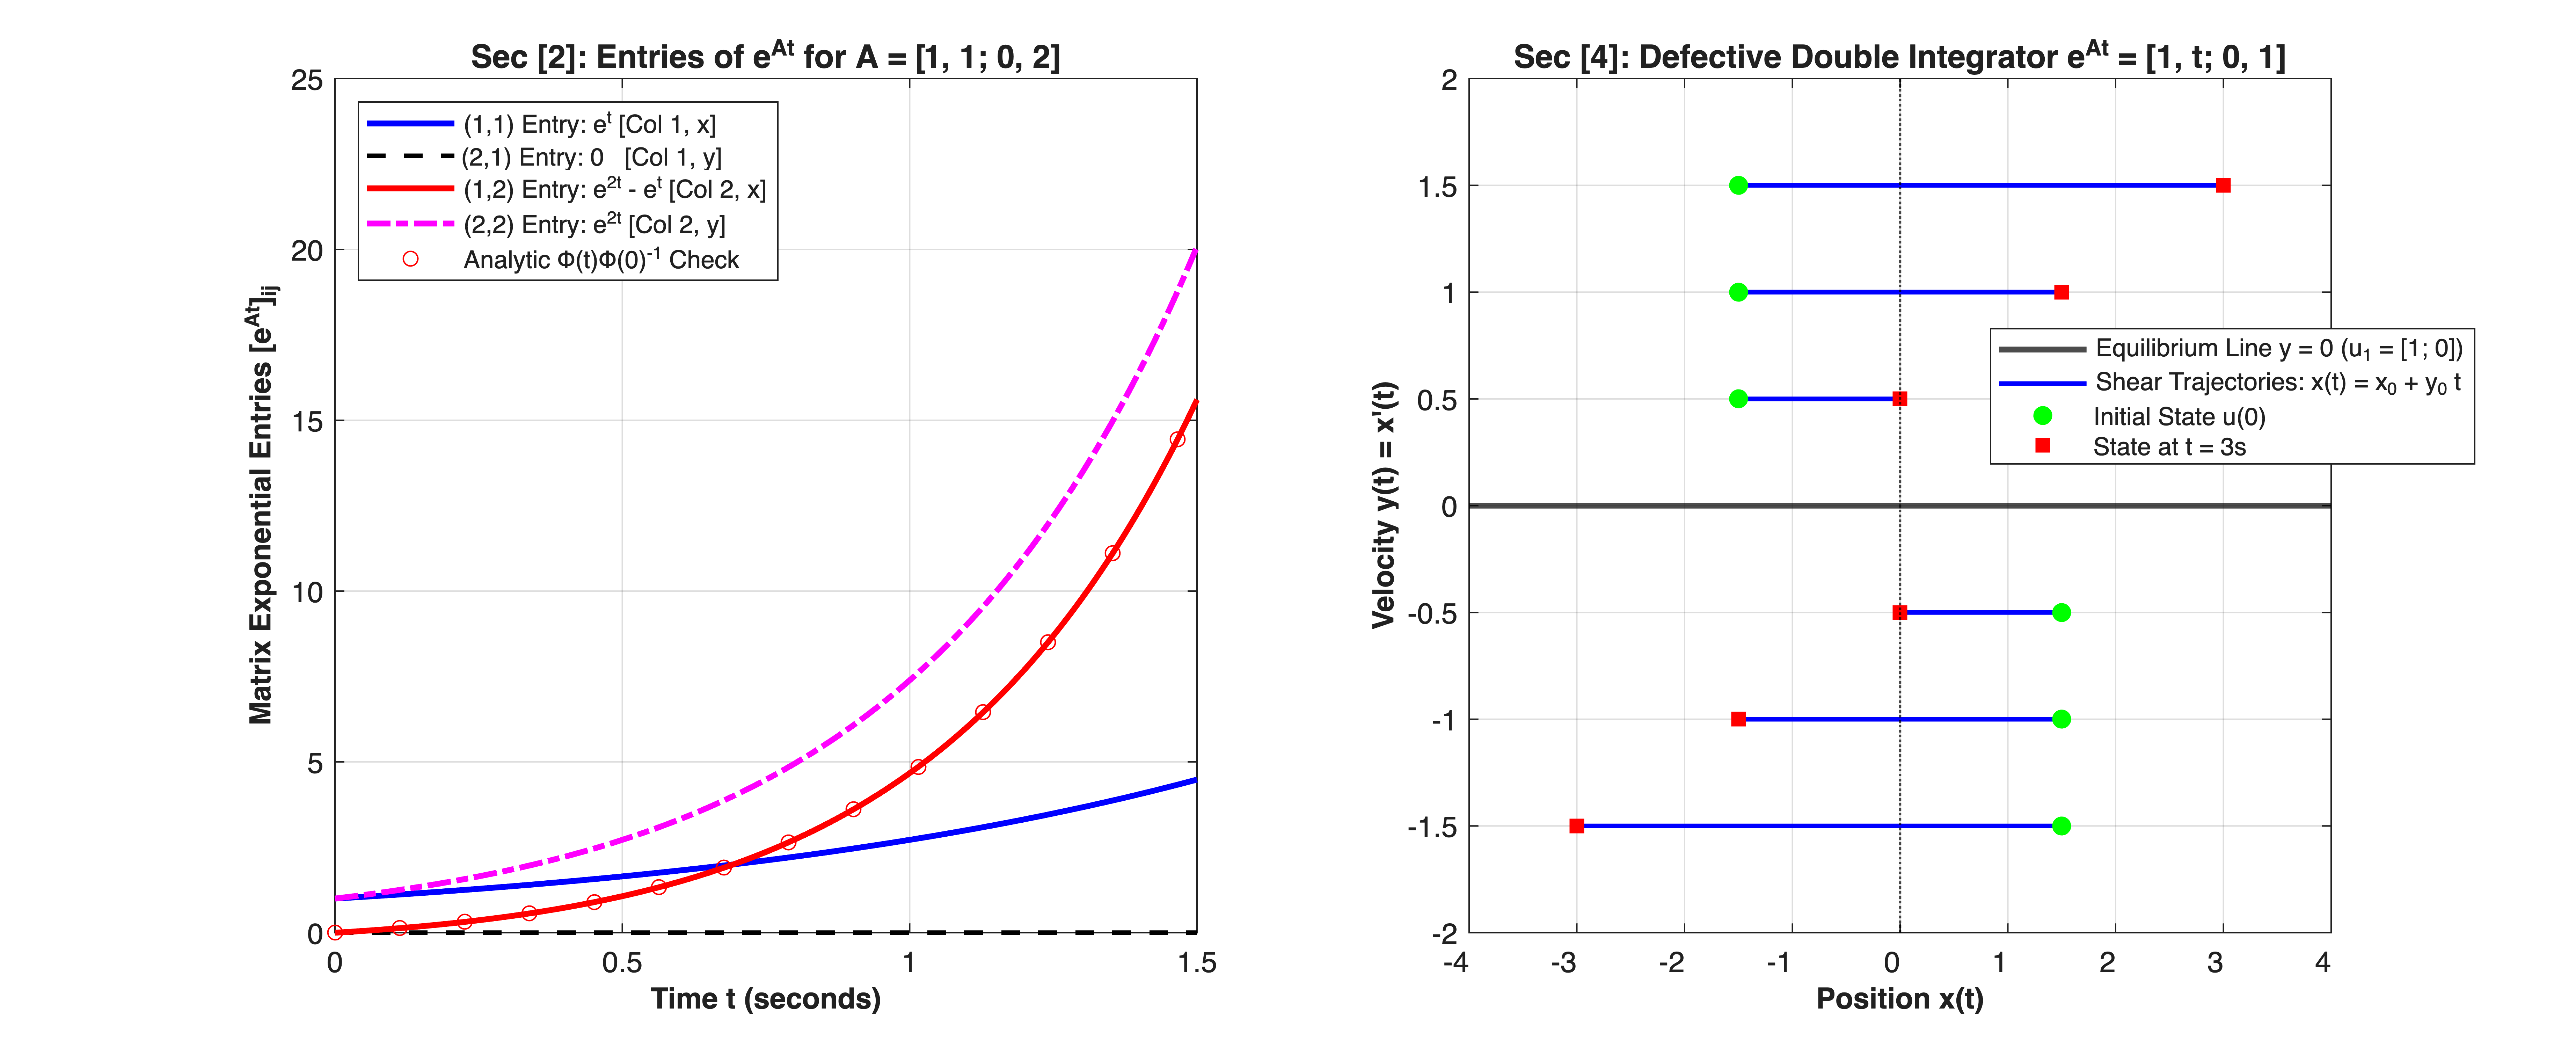

In [15]:


%% =========================================================================
%% Part 3: Visualization of Matrix Exponential Entries & Defective Shear Flow
%% =========================================================================
figure('Color', [1 1 1], 'Position', [80, 80, 1180, 480]);


% Subplot 1: The 4 Entries of e^{A1*t} = [e^t, e^{2t}-e^t ; 0, e^{2t}]
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_vec, col1_sim(:, 1), 'b-',  'LineWidth', 2.0, 'DisplayName', '(1,1) Entry: e^t [Col 1, x]');
plot(t_vec, col1_sim(:, 2), 'k--', 'LineWidth', 1.6, 'DisplayName', '(2,1) Entry: 0   [Col 1, y]');
plot(t_vec, col2_sim(:, 1), 'r-',  'LineWidth', 2.0, 'DisplayName', '(1,2) Entry: e^{2t} - e^t [Col 2, x]');
plot(t_vec, col2_sim(:, 2), 'm-.', 'LineWidth', 2.0, 'DisplayName', '(2,2) Entry: e^{2t} [Col 2, y]');


plot(t_vec(1:30:end), eAt_12_exact(1:30:end), 'ro', 'MarkerSize', 5, ...
     'DisplayName', 'Analytic \Phi(t)\Phi(0)^{-1} Check');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Matrix Exponential Entries [e^{At}]_{ij}', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [2]: Entries of e^{At} for A = [1, 1; 0, 2]', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([0, 1.5]);


% Subplot 2: Phase Plane of Defective Double Integrator A2 = [0, 1; 0, 0]
% u(t) = e^{A2*t} * u(0) = [1, t; 0, 1] * [x0; y0] = [x0 + y0*t; y0]
subplot(1, 2, 2);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Equilibrium Line y = 0 (u_1 = [1; 0])');


t_shear = linspace(0, 3.0, 200);
y0_levels = [-1.5, -1.0, -0.5, 0.5, 1.0, 1.5];
for k = 1:length(y0_levels)
    u0_k = [-1.5 * sign(y0_levels(k)); y0_levels(k)];
    [u_sh, ~] = initial(sys_A2_cont, u0_k, t_shear);
    plot(u_sh(:, 1), u_sh(:, 2), 'b-', 'LineWidth', 1.6, 'HandleVisibility', 'off');
    plot(u0_k(1), u0_k(2), 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 6, 'HandleVisibility', 'off');
    plot(u_sh(end, 1), u_sh(end, 2), 'rs', 'MarkerFaceColor', 'r', 'MarkerSize', 6, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'b-', 'LineWidth', 1.6, 'DisplayName', 'Shear Trajectories: x(t) = x_0 + y_0 t');
plot(NaN, NaN, 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 6, 'DisplayName', 'Initial State u(0)');
plot(NaN, NaN, 'rs', 'MarkerFaceColor', 'r', 'MarkerSize', 6, 'DisplayName', 'State at t = 3s');


xlabel('Position x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Velocity y(t) = x''(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [4]: Defective Double Integrator e^{At} = [1, t; 0, 1]', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([-4, 4]); ylim([-2, 2]);